# PHATE and diffusion maps

*Python port of the R vignettes [PHATE](https://gregorlueg.github.io/manifoldsR/articles/phate.html) and [Diffusion maps](https://gregorlueg.github.io/manifoldsR/articles/diffusion_map.html). Original author: Gregor Lueg.*

The diffusion family. Both model the data as a random walk over a kNN graph
and both were built for continuous structure: trajectories, branch points,
manifolds. [PHATE](https://www.nature.com/articles/s41587-019-0336-3) lays
out potential distances of the diffused walk with MDS,
[diffusion maps](https://doi.org/10.1016/j.acha.2006.04.006) take the
eigenvectors of the diffusion operator directly.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import phate
import polars as pl
from sklearn.decomposition import PCA

import manifolds_rs as mf

warnings.filterwarnings("ignore", message="IProgress not found")
pl.Config.set_fmt_str_lengths(60)


def scatter(
    ax: plt.Axes, emb: np.ndarray, c: np.ndarray, title: str, cmap: str = "tab10"
) -> None:
    """One embedding, coloured by `c`, without axis ticks."""
    ax.scatter(emb[:, 0], emb[:, 1], c=c, s=1, cmap=cmap, alpha=0.6)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


def panels(
    embeddings: dict[str, np.ndarray], c: np.ndarray, cmap: str = "tab10"
) -> None:
    """A row of embeddings sharing one colouring."""
    fig, axes = plt.subplots(
        1, len(embeddings), figsize=(4.3 * len(embeddings), 4.3), squeeze=False
    )
    for ax, (name, emb) in zip(axes[0], embeddings.items(), strict=True):
        scatter(ax, emb, c, name, cmap)
    fig.tight_layout()


def timed(fn) -> float:
    """Wall time of one call, in seconds."""
    start = time.perf_counter()
    fn()
    return time.perf_counter() - start

## PHATE

PHATE runs in steps. An adaptive-bandwidth kernel over the kNN graph, shaped
by `decay`, gives the affinities. Row-normalise and you have a Markov
transition matrix, the diffusion operator. Power it to time `t`, picked at
the knee of the von Neumann entropy unless you pin it. Diffusion denoises:
local noise gets smoothed out and the global geometry comes forward. From the
diffused transition probabilities PHATE computes a **potential distance**,
the difference of their logs (`gamma` sets the exact transform), and lays it
out with MDS.

Against t-SNE and UMAP:

- **Built for continuous structure.** Branching and continuous manifolds
  survive, where t-SNE and UMAP break them into islands.
- **Distances mean a bit more.** The potential distance is a more
  interpretable metric than either of the others. Still don't over-read it.
- **Fails on genuinely discrete clusters.** With no geometry connecting them,
  PHATE looks for a manifold that isn't there.
- **`t` matters.** Too little diffusion and noise dominates, too much and
  the fine structure washes out. The entropy knee works well in practice, but
  look at what you get.

In [2]:
X_clust, y_clust = mf.datasets.clustered(25_000)
X_swiss, t_swiss = mf.datasets.swiss_roll(1_000)
X_traj, y_traj = mf.datasets.trajectory(25_000)
order = np.random.default_rng(42).permutation(len(y_traj))

### Clustered data

The failure mode first, because it's worth seeing.

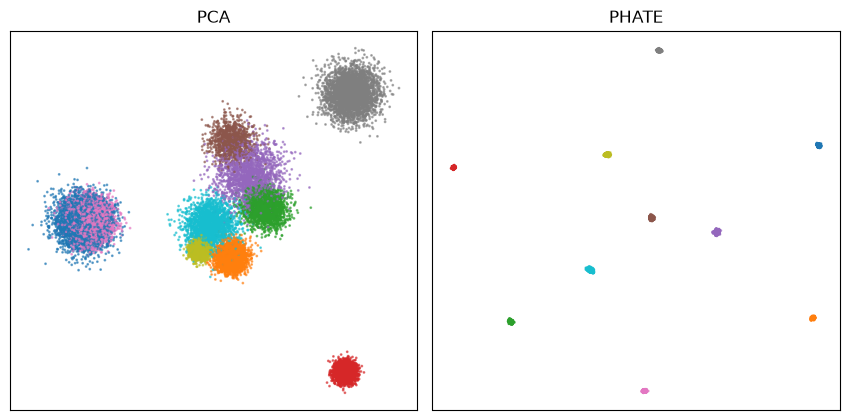

In [3]:
panels(
    {"PCA": PCA(2).fit_transform(X_clust), "PHATE": mf.PHATE().fit_transform(X_clust)},
    y_clust,
)

The clusters get flung outwards and condensed into near points. PHATE is
laying out a manifold that doesn't exist in this data. If yours looks like
this, use t-SNE or UMAP.

### Swiss roll and trajectory

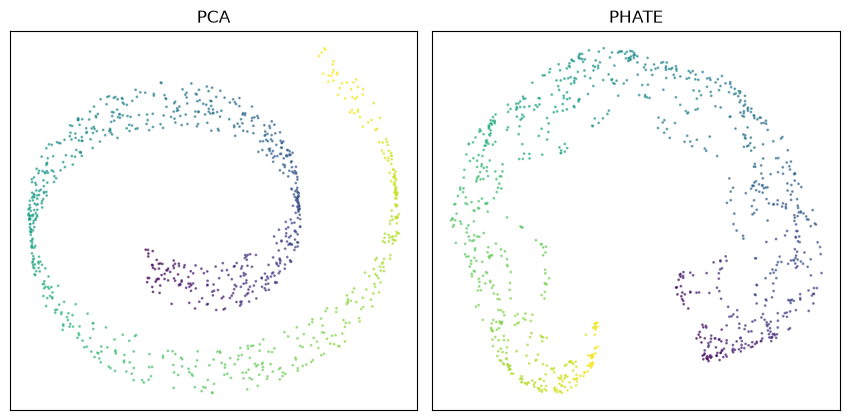

In [4]:
panels(
    {
        "PCA": PCA(2).fit_transform(X_swiss),
        "PHATE": mf.PHATE().fit_transform(X_swiss),
    },
    t_swiss,
    cmap="viridis",
)

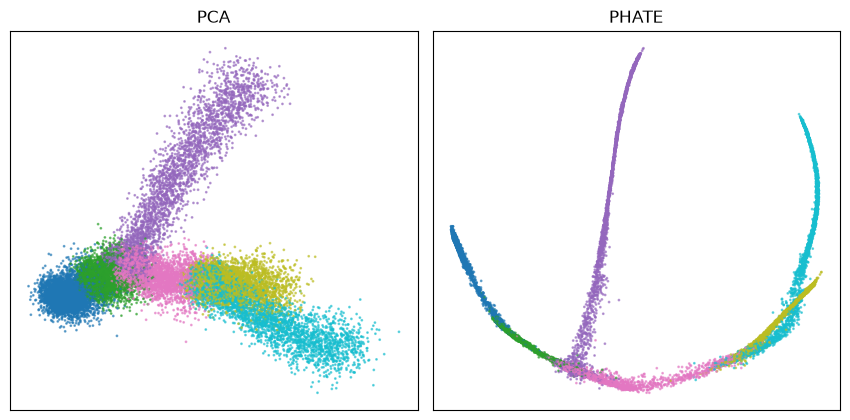

In [5]:
panels(
    {
        "PCA": PCA(2).fit_transform(X_traj)[order],
        "PHATE": mf.PHATE().fit_transform(X_traj)[order],
    },
    y_traj[order],
)

This is the data PHATE was built for. The branches come out as branches,
the progression along each one is kept and the branch points are where you
would look for them.

### Pre-computed kNN graphs

PHATE needs a wider graph than `k`: neighbours past the `k`-th join the
kernel while their affinity clears the threshold, so the internal search runs
`6 * k + 5` wide. Give a pre-computed graph the same width. With the graph
fixed, pinning `t` is cheap to try.

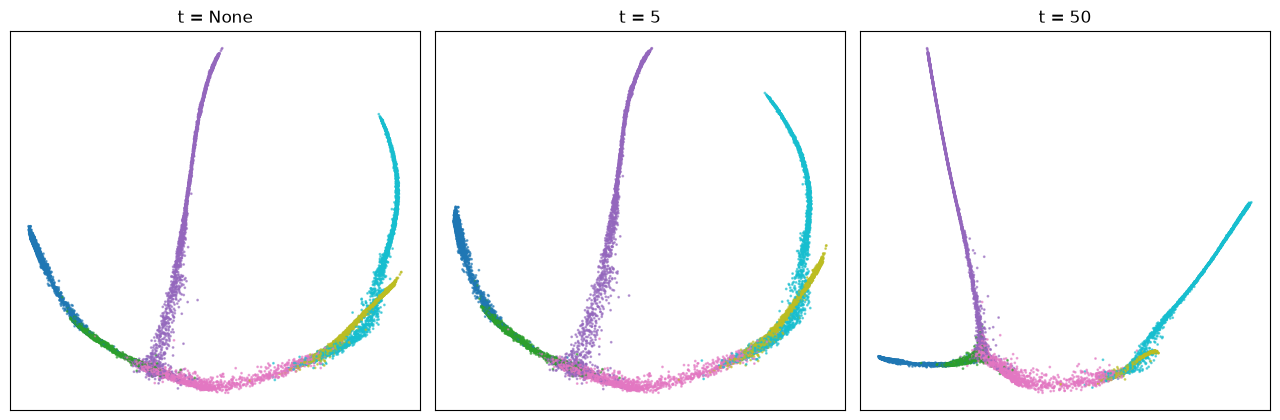

In [6]:
k = 5
idx, dist = mf.knn_graph(X_traj, k=6 * k + 5, ann="ivf")

panels(
    {
        f"t = {t}": mf.PHATE(k=k, t=t).fit_transform(
            X_traj, knn_indices=idx, knn_distances=dist
        )[order]
        for t in (None, 5, 50)
    },
    y_traj[order],
)

`t = None` is the entropy knee, and it lands close to `t = 5` here. At
`t = 50` the arcs straighten out and two of the early branches get squeezed
into one line: fine structure washing out.

### Landmarks

The full diffusion operator is `N x N`, and so is the dense potential
distance matrix. Landmarks get around that: pick a representative subset,
diffuse over it only, and interpolate everything else in. The default is 2048
landmarks (a power of two, for the SIMD in the k-means underneath).
`landmark_method` picks them:

- `"spectral"` (default): spectral clustering on the affinity graph. The most
  representative coverage on complex topology, and the most expensive.
- `"random"`: uniform. Fast, uneven coverage when the density varies.
- `"density"`: drawn by dampened node degree. A bit more careful than random,
  but rare branches can be missed.

500 to 2000 landmarks cover most data up to a few hundred thousand points.
Too few and the interpolation misses fine structure, too many and the speed
advantage goes. `n_landmarks=None` runs the full operator, which gets nasty
fast on large data.

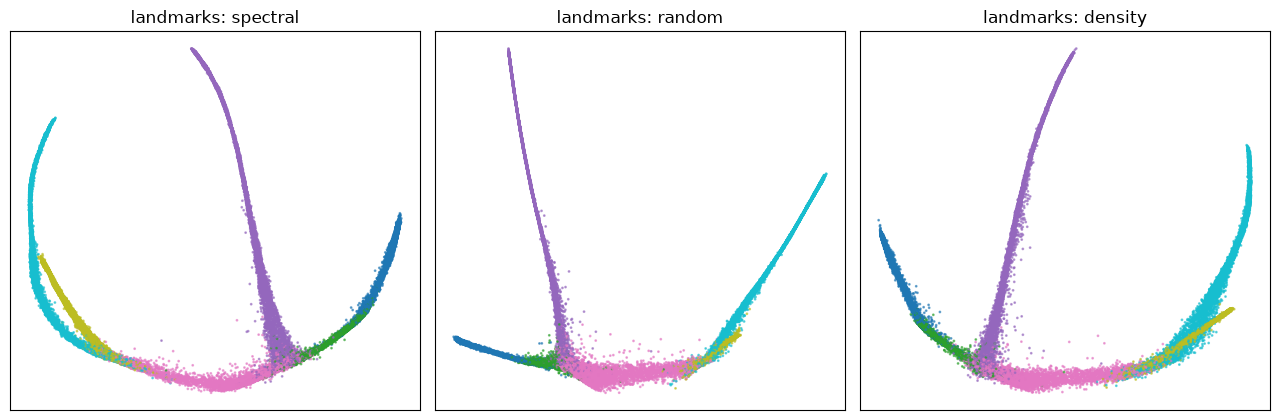

In [7]:
X_big, y_big = mf.datasets.trajectory(100_000)
order_big = np.random.default_rng(42).permutation(len(y_big))

panels(
    {
        f"landmarks: {m}": mf.PHATE(landmark_method=m).fit_transform(X_big)[order_big]
        for m in ("spectral", "random", "density")
    },
    y_big[order_big],
)

Same tree three times, mirrored and rotated. The density landmarks squash the
stem a bit more than the other two.

## Diffusion maps

Same early pipeline as PHATE: a kNN graph, an adaptive Gaussian kernel, and an
anisotropic normalisation (`alpha`) that corrects for uneven sampling. The
result is a row-stochastic operator `P`, a random walk on the manifold. Then
the paths split. Instead of diffusing for `t` steps and computing potential
distances, diffusion maps eigendecompose the symmetric form of `P`. The top
non-trivial eigenvectors are the coordinates, scaled by $\lambda_k^t$, so `t`
ends up as an exponent on the eigenvalues: larger `t` favours the dominant
directions, smaller `t` keeps more detail.

`alpha` is the distinctive knob. `0` gives the normalised graph Laplacian,
`0.5` the Fokker-Planck operator, `1` (default) the Laplace-Beltrami
operator, which recovers the manifold geometry independent of the sampling
density.

Against PHATE:

- **More transparent.** The coordinates are eigenvectors of a well-defined
  operator, orthogonal and ordered by importance.
- **Different look.** Axis-aligned, symmetric, horseshoes on linear
  trajectories where PHATE looks organic.
- **Different failure on clusters.** With near-disconnected clusters the top
  eigenvectors approximate cluster indicators.
- **No MDS step**, so the embedding is fixed once the operator is.

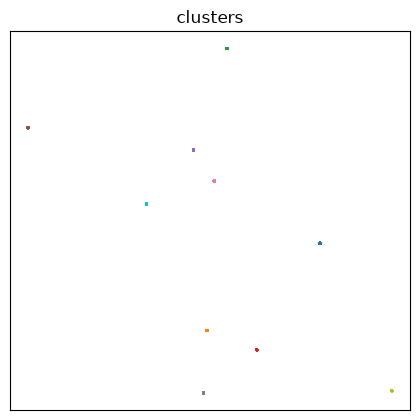

In [8]:
panels(
    {
        "clusters": mf.DiffusionMaps().fit_transform(X_clust),
    },
    y_clust,
)

Each cluster collapses to roughly one point: the eigenvectors are near
constant within a cluster. PHATE shows the same problem less aggressively,
because the log and the MDS keep a little spread. With ten near-disconnected
components the spectrum has about ten eigenvalues close to 1, and two
dimensions can't separate them all, hence the clusters crowding the middle. Diffusion maps
collapsing harder than PHATE on your data is a signal in itself: it is more
cluster than manifold. Reach for t-SNE, UMAP or PaCMAP.

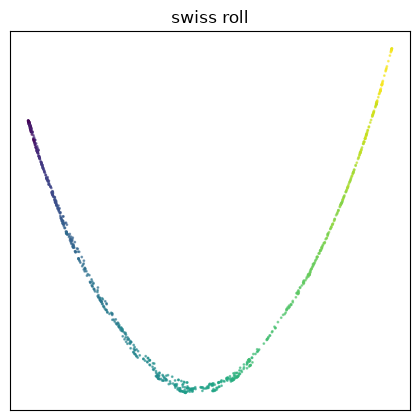

In [9]:
panels(
    {"swiss roll": mf.DiffusionMaps().fit_transform(X_swiss)},
    t_swiss,
    cmap="viridis",
)

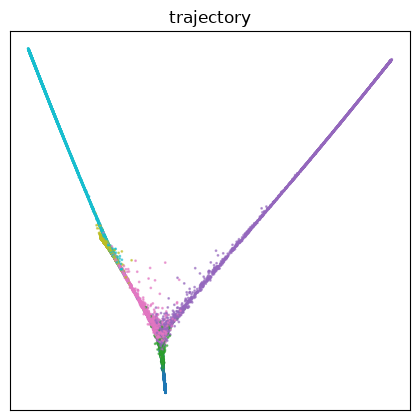

In [10]:
panels(
    {"trajectory": mf.DiffusionMaps().fit_transform(X_traj)[order]},
    y_traj[order],
)

The swiss roll is the textbook case for diffusion maps, one of the canonical
examples in the original paper. On the trajectory the branches come out as
distinct directions, more orthogonal-looking than in PHATE. Both are valid
pictures of the same structure.

Pre-computed graphs work as everywhere else. With the graph fixed, iterate on
`alpha`, `t` and `bandwidth_scale` at no search cost.

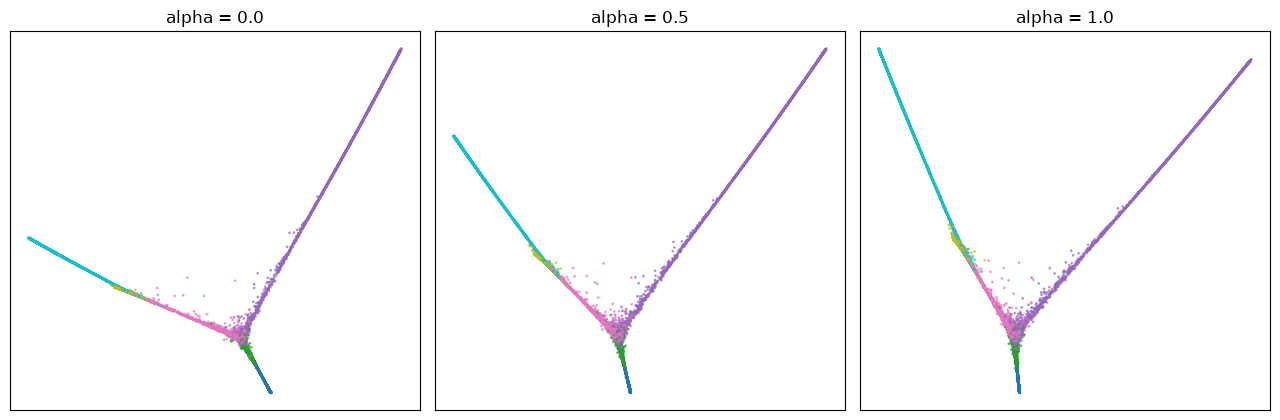

In [11]:
idx_dm, dist_dm = mf.knn_graph(X_traj, k=5, ann="nndescent")

panels(
    {
        f"alpha = {a}": mf.DiffusionMaps(alpha=a).fit_transform(
            X_traj, knn_indices=idx_dm, knn_distances=dist_dm
        )[order]
        for a in (0.0, 0.5, 1.0)
    },
    y_traj[order],
)

### Landmarks

The same landmark machinery as PHATE: pick a subset, eigendecompose the
`L x L` landmark operator, Nystroem-extend back to everything. Unlike PHATE
it is off by default. The full operator stays sparse and goes to a sparse
eigensolver, while the landmark operator is dense, so on moderate data the
full operator is the faster one. Landmarks are for data where the full
operator no longer fits comfortably.

method,seconds
str,f64
"""full operator""",1.22
"""spectral landmarks""",7.17
"""random landmarks""",1.34


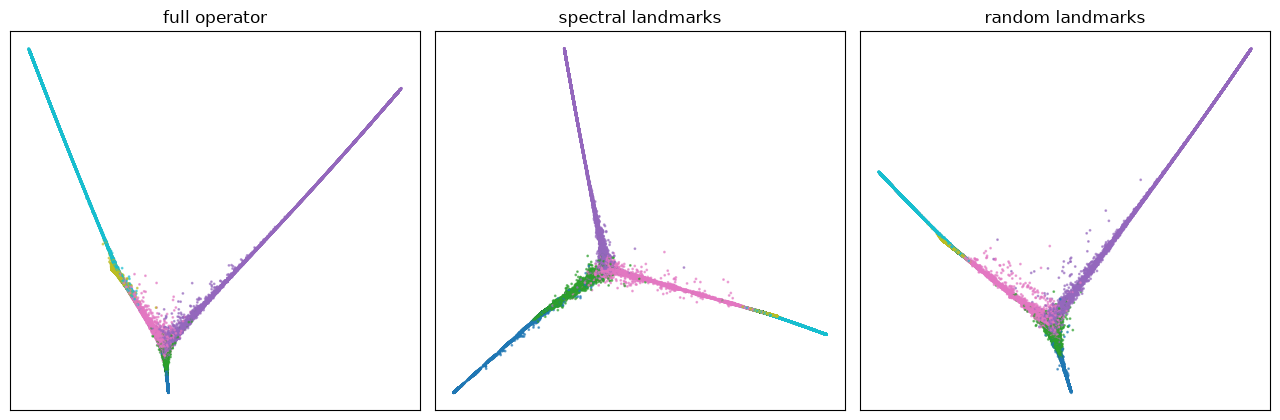

In [12]:
dm_big = {
    "full operator": mf.DiffusionMaps(),
    "spectral landmarks": mf.DiffusionMaps(n_landmarks=2048),
    "random landmarks": mf.DiffusionMaps(n_landmarks=2048, landmark_method="random"),
}
dm_times = {}
dm_embs = {}
for name, est in dm_big.items():
    start = time.perf_counter()
    dm_embs[name] = est.fit_transform(X_big)[order_big]
    dm_times[name] = time.perf_counter() - start

panels(dm_embs, y_big[order_big])
pl.DataFrame(
    {"method": list(dm_times), "seconds": list(dm_times.values())}
).with_columns(pl.col("seconds").round(2))

Timings on 100k points, one run each. The full operator wins, random
landmarks come close, and the spectral selection costs several times more:
it is there for the topology, not the speed.

## Benchmarks

PHATE against the reference [phate](https://github.com/KrishnaswamyLab/PHATE)
package, on all cores, one run each, wall time in seconds. Both run their
defaults: `k = 5`, around 2000 landmarks, entropy-picked `t`.

In [13]:
def bench(x: np.ndarray) -> pl.DataFrame:
    """Wall time of our PHATE and the reference on `x`."""
    runs = {
        "manifolds-rs PHATE spectral": lambda: mf.PHATE().fit_transform(x),
        "manifolds-rs PHATE random": lambda: mf.PHATE(
            landmark_method="random"
        ).fit_transform(x),
        "phate": lambda: phate.PHATE(
            n_jobs=-1, random_state=42, verbose=False
        ).fit_transform(x),
    }
    return pl.DataFrame(
        [{"method": k, "seconds": timed(fn)} for k, fn in runs.items()]
    ).with_columns(pl.col("seconds").round(2))


bench(mf.datasets.trajectory(10_000)[0])

method,seconds
str,f64
"""manifolds-rs PHATE spectral""",2.62
"""manifolds-rs PHATE random""",1.88
"""phate""",7.03


In [14]:
bench(mf.datasets.trajectory(50_000)[0])

method,seconds
str,f64
"""manifolds-rs PHATE spectral""",5.52
"""manifolds-rs PHATE random""",2.1
"""phate""",11.11


Both the spectral and the random landmark versions beat the reference at
both sizes, random by the widest margin. Neighbour search, kernel, diffusion
time, potential distances and MDS all stay in Rust.